# S3 · Integrity scandal at the top: effect on trust, estimated on the EU panel

**What this notebook does.** It estimates how trust in government, parliament and parties, and satisfaction with democracy, move after an **integrity scandal that reaches the top** (a head of government, head of state or whole cabinet leaves office over corruption, abuse of office or ethics allegations). It uses every EU country and every Eurobarometer wave since 2001. The design, controls and tests follow the S1 and E notebooks so the three shocks can be compared.

**The shock (scope documents).** The Scope Review and the MVP update name the scenario *"Integrity scandal at the top"*, with Austria 2019 (Ibiza), Spain 2018 (Gürtel) and Italy 1992–94 as the reference episodes, and trust in parties and government and the party system as the main variables hit. Austria 2019 and Spain 2018 also brought down governments; **they are counted under S3 only**, so no episode is used twice. (The newer *MVP data specification* parks this scenario for now; this notebook builds it as the third scenario.)

**There is no monthly "scandal" statistic**, unlike energy prices. The shock has to be built from dated events. The list is in `data/reference/s3_events.csv`: **22 scandal exits** in 18 EU countries, 2005–2025, each with its decisive date, the level reached, and news links. It is a team-checkable table, not an automatic count, and **its selection rule is the main limit of this notebook** (see the end).

**Rules shared with the S1 and E notebooks**
- A case that is read or tested is never used to estimate. Every effect is estimated **without France**. France has no scandal exit in the sample, so its readings are what-ifs, and two French scandals without an exit (Cahuzac 2013, Fillon 2017) are shown as an informal check.
- Country and wave fixed effects, the controls named in the specification, exact timing (baseline = mean of the two waves before; the "after" wave must start at least 30 days after the event), and **wild cluster bootstrap** ranges.
- A change inside the survey noise (about ±4.4 points) is *no detectable change*, not a direction.
- The back-test leaves out one country at a time and is scored against a **"no change" baseline**, with calibrated (conformal) ranges for a single episode.

In [1]:
import json, zipfile, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
OUTDIR = ROOT / 'outputs/model'
OUTDIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / 'src'))
pd.set_option('display.max_columns', 40, 'display.width', 230, 'display.max_rows', 200, 'display.max_colwidth', 70)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
BLUE, GREY, RED, LIGHT, ORANGE, GREEN = '#2b6cb0', '#8a8f98', '#c53030', '#e8ecf1', '#dd8a2e', '#2a8c82'

NOISE = 4.4
HORIZONS = [1, 2, 3, 4]
OUTCOMES = {'trust_gov': 'Trust in government', 'trust_parl': 'Trust in parliament', 'trust_parties': 'Trust in political parties', 'swd': 'Satisfied with democracy'}
HELD_OUT = 'FRA'
START_WAVE = pd.Timestamp('2001-03-01')
MATCH_DAYS = 150                  # an ending within 150 days of a scandal exit is that exit, not a separate cabinet change

## 1. The events

Each row is a **scandal exit**: a head of government, a head of state or the whole cabinet leaves office, and the reason reported at the time is an integrity allegation (corruption, conflict of interest, abuse of office, an ethics breach). The **decisive date** is the day the exit became public (resignation announced, or the confidence vote lost). The **level** is how far it went:

- `government_fell`: the government ended in a way that changed who governs (a different coalition, a caretaker or technocratic cabinet, or an early election);
- `pm_resigned`: the head of government left but the same party or coalition kept the premiership with no early election;
- `head_of_state`: a president resigned and the government was not affected.

Every row carries evidence links, and `checked_by_person` is `no`: the dates and the coding of the level are one reviewer's, to be confirmed by the team. Two rows are borderline cases and are tested with and without: the Dutch childcare-benefits scandal (institutional wrongdoing, not personal corruption) and the three head-of-state cases.

In [2]:
ev = pd.read_csv(ROOT / 'data/reference/s3_events.csv', parse_dates=['decisive_date'])
ev['hos'] = (ev.level == 'head_of_state').astype(float)
ev['institutional'] = (ev.trigger_type == 'institutional').astype(float)
events = ev[ev.iso3 != HELD_OUT].reset_index(drop=True)
print(f"{len(ev)} events in {ev.iso3.nunique()} countries, {ev.decisive_date.min():%b %Y} to {ev.decisive_date.max():%b %Y}; France: {int((ev.iso3 == HELD_OUT).sum())}")
display(ev[['event_id', 'decisive_date', 'level', 'trigger_type', 'confidence']].assign(decisive_date=lambda d: d.decisive_date.dt.date).set_index('event_id'))
print(ev.groupby('level').size().to_dict(), '| by trigger:', ev.groupby('trigger_type').size().to_dict())

22 events in 18 countries, Apr 2005 to Jul 2025; France: 0


,decisive_date,level,trigger_type,confidence
event_id,,,,
CZE_2005_Gross,2005-04-25,pm_resigned,personal,high
LVA_2007_Kalvitis,2007-11-07,pm_resigned,abuse_of_office,high
IRL_2008_Ahern,2008-04-02,pm_resigned,personal,medium
BEL_2008_Leterme,2008-12-19,pm_resigned,abuse_of_office,high
DEU_2012_Wulff,2012-02-17,head_of_state,personal,high
HUN_2012_Schmitt,2012-04-02,head_of_state,ethics,medium
SVN_2013_Jansa,2013-02-27,government_fell,personal,high
CZE_2013_Necas,2013-06-17,government_fell,aide,high
LUX_2013_SREL,2013-07-10,government_fell,abuse_of_office,medium


{'government_fell': 11, 'head_of_state': 3, 'pm_resigned': 8} | by trigger: {'abuse_of_office': 4, 'aide': 1, 'coalition_partner': 1, 'conflict_of_interest': 1, 'ethics': 1, 'institutional': 1, 'murder_of_journalist': 2, 'party': 2, 'personal': 9}


## 2. The panel and the controls

Same panel as the other notebooks: trust and satisfaction from `data/processed/eb_panel.csv`, one row per country and wave, EU members only while members. Controls: country and wave fixed effects; unemployment, growth and inflation in the year before the wave; the trust trend over the previous wave; and the other shocks, so each effect is net of them (specification, section 4):

| Control | Why |
| --- | --- |
| Another cabinet ending in the same interval | A scandal exit is itself a cabinet change. An **ordinary** change (not matched to a scandal) is a separate nuisance |
| An S1 government fall that is **not** a scandal | The effect of a scandal exit is measured **beyond** an ordinary government fall, not on top of it. This is the main difference from S1 |
| Country under an EC/IMF bailout (S2) | The financial-crisis shock |
| Country inside an energy surge (E) | The 2021–23 and 2005–12 energy surges overlap some events (Estonia, Netherlands and Austria 2021) |

An ending within 150 days of a scandal exit is treated as that exit and is not counted as a separate cabinet change or fall.

In [3]:
with zipfile.ZipFile(ROOT / 'data/raw/ppeg_2025v1/ppeg_gov_2025v1.zip') as z:
    members = pd.read_csv(z.open('ppeg_gov_2025v1.csv'), low_memory=False, usecols=['iso3c', 'iso2c', 'eu_since', 'eu_exit']).drop_duplicates('iso3c')
members = members[members.eu_since.notna()]
iso3_of = dict(zip(members.iso2c, members.iso3c))
eu_since, eu_exit = members.set_index('iso3c').eu_since, members.set_index('iso3c').eu_exit

panel = pd.read_csv(ROOT / 'data/processed/eb_panel.csv', parse_dates=['fieldwork_median', 'fieldwork_start', 'fieldwork_end'])
panel['iso3'] = panel.country.map(iso3_of)
panel = panel.dropna(subset=['iso3'])
yr = panel.fieldwork_median.dt.year
panel = panel[(yr >= panel.iso3.map(eu_since)) & (panel.iso3.map(eu_exit).isna() | (yr < panel.iso3.map(eu_exit)))]
macro = pd.read_csv(ROOT / 'data/processed/eurostat_macro_country_year.csv')
macro['country'] = macro.geo.replace({'EL': 'GR', 'UK': 'GB'})
macro = macro.rename(columns={'nama_10_gdp_real_growth': 'growth', 'une_rt_a_unemployment': 'unemployment', 'prc_hicp_aind_inflation': 'inflation'})
panel['macro_year'] = panel.fieldwork_median.dt.year - 1
panel = panel.merge(macro[['country', 'year', 'growth', 'unemployment', 'inflation']], left_on=['country', 'macro_year'], right_on=['country', 'year'], how='left')
panel = panel.sort_values(['iso3', 'fieldwork_median']).reset_index(drop=True)

# cabinet endings, split into: matched to a scandal exit / ordinary S1 fall / other ordinary change
endings = pd.read_csv(ROOT / 'data/processed/s1_all_endings_dataset.csv', parse_dates=['event_date'])
S1_GROUPS = {'government collapse', 'collapse after a scandal', 'collapse in a financial crisis'}
endings['s1_fall'] = endings.case_group.isin(S1_GROUPS) | ((endings.case_group == 'PPEG: cabinet dissension') & (endings.s1_status == 'include'))
endings = endings[endings.case_group != 'failed government formation'].copy()
endings['is_s3'] = [bool(((ev.iso3 == r.iso3) & ((ev.decisive_date - r.event_date).abs() <= pd.Timedelta(days=MATCH_DAYS))).any()) for r in endings.itertuples()]
print(f"{int(endings.is_s3.sum())} PPEG/reviewed endings are matched to a scandal exit; {int((endings.s1_fall & ~endings.is_s3).sum())} ordinary S1 falls and {int((~endings.s1_fall & ~endings.is_s3).sum())} other ordinary endings are controls")

# S2: bailout windows
prog = pd.read_csv(ROOT / 'data/reference/s2_bailout_programmes_ec_imf.csv')
prog = prog[prog.drawn == 'yes'].assign(geo=lambda d: d.geo.replace({'EL': 'GR'}))
prog['start'] = pd.to_datetime(prog.approved)
prog['end'] = pd.to_datetime(prog.last_disbursement.astype(str).str[:7] + '-28', errors='coerce')
esm = pd.read_csv(ROOT / 'data/processed/s2_bailout_programmes.csv'); spain = esm[esm.country.str.startswith('Spain')]
bail = pd.concat([prog[['geo', 'start', 'end']], pd.DataFrame({'geo': ['ES'] * len(spain), 'start': pd.to_datetime(spain.first_disbursement), 'end': pd.to_datetime(spain.last_disbursement)})])
bail = bail.dropna(subset=['start', 'end']).assign(iso3=lambda d: d.geo.map(iso3_of)).groupby('iso3').agg(start=('start', 'min'), end=('end', 'max'))

# E: energy surges (from the E notebook's output)
espells = pd.read_csv(OUTDIR / 'e_spells.csv')
espells['s'] = pd.PeriodIndex(espells.start, freq='M').to_timestamp()
espells['e'] = pd.PeriodIndex(espells.end, freq='M').to_timestamp(how='end')

# elections (for the clean-event check and the party-system section)
import build_s1_dataset as b1
elections = b1.election_table()
print(f"{panel.iso3.nunique()} countries, {panel.za.nunique()} waves; {len(elections)} parliamentary elections")

19 PPEG/reviewed endings are matched to a scandal exit; 37 ordinary S1 falls and 75 other ordinary endings are controls


28 countries, 56 waves; 1100 parliamentary elections


## 3. The model

For each outcome and horizon *h* (the *h*-th Eurobarometer wave starting at least 30 days after the exit), one regression on the panel, the same local-projection form as S1 and E:

> change in the outcome from the two waves before to *h* waves after = **scandal exit** + **× government fell** + later exit + other cabinet change + ordinary S1 fall + bailout + energy surge + trend + economy + country effects + wave effects

- **Scandal exit** is the base effect: the person at the top (a head of government, or a head of state) leaves over an integrity scandal and the government carries on with the same coalition. The second term says what is *added* when the **government fell** (a different coalition, a caretaker or technocratic cabinet, or an early election). Head-of-state exits are only three, so they sit in the base and are tested without in section 6. Splitting 13 exits further would leave two or three in a group, and a bootstrap range on two or three events means nothing.
- An **event** row is a country-wave with a scandal exit in the interval since the previous wave and none in the interval before; a **control** row has no scandal exit from the interval before until the end of the horizon. Rows too close to a wave (less than 30 days) are left out.
- **Placebo (h = 0):** the same on the change *before* the exit; it should be about zero.
- Standard errors clustered by country; ranges are wild cluster bootstrap-t, 90%.

In [4]:
CONTROLS = ['later_on', 'other_change', 'fall_other', 'bailout', 'energy_exposed', 'pre_trend', 'growth', 'unemployment', 'inflation']
SHOCK = ['on', 'gov_fell']

def build_sample(outcome, h, exact=True, events_df=None, use_controls=True):
    evs = events if events_df is None else events_df
    rows = []
    for iso3, d in panel[panel[outcome + '_pct'].notna()].groupby('iso3'):
        d = d.reset_index(drop=True)
        y, t = d[outcome + '_pct'].to_numpy(), d.fieldwork_median.to_numpy()
        E = evs[evs.iso3 == iso3].reset_index(drop=True)
        n_ev = np.zeros(len(t), int); ev_at = {}
        for i, r in E.iterrows():
            j = int(np.searchsorted(t, np.datetime64(r.decisive_date), side='left'))   # interval (t[j-1], t[j]]
            if 1 <= j < len(t):
                n_ev[j] += 1; ev_at[j] = r
        en = endings[endings.iso3 == iso3]
        sp = espells[espells.iso3 == iso3]
        hh = max(h, 1)
        for k in range(3 if exact else 2, len(d) - hh + 1):
            if t[k] < np.datetime64(START_WAVE):
                continue
            lo = k - 2 if h == 0 else k - 1
            is_event = n_ev[k] > 0 and n_ev[lo:k].sum() == 0
            is_control = n_ev[lo:k + hh].sum() == 0
            if not (is_event or is_control):
                continue
            r = ev_at.get(k) if is_event else None
            if is_event and exact:
                st = r.decisive_date
                if not (d.fieldwork_start[k] >= st + pd.Timedelta(days=30) and d.fieldwork_end[k - 1] < st):
                    continue
            ed = en[(en.event_date > t[k - 1]) & (en.event_date <= t[k]) & ~en.is_s3]
            bl = bail.loc[iso3] if iso3 in bail.index else None
            expo = bool(((sp.s <= t[k]) & (sp.e >= t[k - 1])).any()) if len(sp) else False
            base = ((y[k - 2] + y[k - 3]) / 2 if h == 0 else (y[k - 1] + y[k - 2]) / 2) if exact else (y[k - 2] if h == 0 else y[k - 1])
            after = y[k - 1] if h == 0 else y[k + h - 1]
            rows.append({'iso3': iso3, 'wave': d.za[k], 'date': t[k], 'dy': after - base, 'on': float(is_event),
                         'gov_fell': float(r.gov_fell) if is_event else 0.0, 'hos': float(r.hos) if is_event else 0.0,
                         'institutional': float(r.institutional) if is_event else 0.0, 'event_id': r.event_id if is_event else '',
                         'later_on': float(is_event and h > 1 and n_ev[k + 1:k + h].sum() > 0),
                         'other_change': float((~ed.s1_fall).any()) if use_controls else 0.0, 'fall_other': float(ed.s1_fall.any()) if use_controls else 0.0,
                         'bailout': float(use_controls and bl is not None and bl.start <= pd.Timestamp(t[k]) and bl.end > pd.Timestamp(t[k - 1])),
                         'energy_exposed': float(use_controls and expo), 'pre_trend': y[k - 1] - y[k - 2],
                         'growth': d.growth[k], 'unemployment': d.unemployment[k], 'inflation': d.inflation[k]})
    s = pd.DataFrame(rows)
    return s.dropna(subset=['growth', 'unemployment', 'inflation']).reset_index(drop=True)

def design(s, h=1, shock=SHOCK, controls=CONTROLS):
    ctl = [c for c in controls if not (c == 'pre_trend' and h == 0) and not (c == 'later_on' and h <= 1)]
    X = s[shock + ctl].copy()
    X = pd.concat([X, pd.get_dummies(s.iso3, prefix='c', drop_first=True, dtype=float), pd.get_dummies(s.wave, prefix='w', drop_first=True, dtype=float)], axis=1)
    X.insert(0, 'const', 1.0)
    return X.astype(float)

def ols_cluster(y, X, groups):
    Xv, yv = X.to_numpy(), y.to_numpy()
    XtX_inv = np.linalg.pinv(Xv.T @ Xv)
    b = XtX_inv @ Xv.T @ yv
    u = yv - Xv @ b
    meat = np.zeros((Xv.shape[1], Xv.shape[1]))
    for g in np.unique(groups):
        sg = Xv[groups == g].T @ u[groups == g]
        meat += np.outer(sg, sg)
    n, k, G = len(yv), Xv.shape[1], len(np.unique(groups))
    V = XtX_inv @ meat @ XtX_inv * G / (G - 1) * (n - 1) / (n - k)
    return pd.Series(b, X.columns), pd.DataFrame(V, X.columns, X.columns), u, G

def t90(df):
    z = 1.6448536
    return z + (z**3 + z) / (4 * df) + (5 * z**5 + 16 * z**3 + 3 * z) / (96 * df**2)

def wild_ci(model, combos, B=999, seed=20261124, alpha=0.10):
    # Percentile-t wild cluster bootstrap (Rademacher weights, unrestricted residuals) for linear combinations of the coefficients
    X, y, u, b = model['X'].to_numpy(), model['s'].dy.to_numpy(), model['u'], model['b'].to_numpy()
    _, inv = np.unique(model['s'].iso3.to_numpy(), return_inverse=True)
    G = inv.max() + 1
    D = np.zeros((len(y), G)); D[np.arange(len(y)), inv] = 1.0
    XtXi = np.linalg.pinv(X.T @ X)
    n, k = X.shape
    adj = G / (G - 1) * (n - 1) / (n - k)
    C = np.atleast_2d(np.asarray(combos, float)); P = C @ XtXi; theta = C @ b
    se_of = lambda uvec: np.sqrt(adj * ((D.T @ (X * uvec[:, None]) @ P.T) ** 2).sum(axis=0))
    se0 = se_of(u)
    rng = np.random.default_rng(seed); fitted = X @ b
    T = np.empty((B, len(C)))
    for i in range(B):
        ys = fitted + rng.choice([-1.0, 1.0], size=G)[inv] * u
        bs = XtXi @ (X.T @ ys)
        T[i] = (C @ bs - theta) / se_of(ys - X @ bs)
    qlo, qhi = np.nanquantile(T, [alpha / 2, 1 - alpha / 2], axis=0)
    return theta, theta - qhi * se0, theta - qlo * se0

_CACHE = {}
def sample(outcome, h, **kw):
    key = (outcome, h, tuple(sorted((k, str(v)) for k, v in kw.items())))
    if key not in _CACHE:
        _CACHE[key] = build_sample(outcome, h, **kw)
    return _CACHE[key]

def fit(outcome, h, exclude=(HELD_OUT,), shock=SHOCK, controls=CONTROLS, **kw):
    s = sample(outcome, h, **kw)
    s = s[~s.iso3.isin(exclude)].reset_index(drop=True)
    X = design(s, h=h, shock=shock, controls=controls)
    b, V, u, G = ols_cluster(s.dy, X, s.iso3.to_numpy())
    return {'s': s, 'X': X, 'b': b, 'V': V, 'u': u, 'G': G, 'shock': shock, 'n_events': int(s.on.sum()), 'n_obs': len(s), 'event_countries': int(s[s.on == 1].iso3.nunique())}

models = {(o, h): fit(o, h) for o in OUTCOMES for h in [0] + HORIZONS}
print('Scandal exits and country-waves behind each regression (France excluded):')
display(pd.DataFrame({f'h = {h}' if h else 'placebo': {OUTCOMES[o]: f"{models[(o, h)]['n_events']} exits / {models[(o, h)]['n_obs']} rows" for o in OUTCOMES} for h in [0] + HORIZONS}))
used = sample('trust_gov', 2); used = used[(used.on == 1) & (used.iso3 != HELD_OUT)]
print(f"Events lost to the 30-day timing rule or a missing wave at h = 2: {len(events) - len(used)} of {len(events)}: " + ', '.join(sorted(set(events.event_id) - set(used.event_id))))

Scandal exits and country-waves behind each regression (France excluded):


,placebo,h = 1,h = 2,h = 3,h = 4
Trust in government,14 exits / 1171 rows,14 exits / 1191 rows,13 exits / 1145 rows,13 exits / 1101 rows,13 exits / 1058 rows
Trust in parliament,14 exits / 1158 rows,14 exits / 1178 rows,13 exits / 1132 rows,13 exits / 1088 rows,13 exits / 1045 rows
Trust in political parties,15 exits / 1059 rows,15 exits / 1078 rows,14 exits / 1033 rows,14 exits / 989 rows,14 exits / 946 rows
Satisfied with democracy,15 exits / 914 rows,15 exits / 934 rows,14 exits / 888 rows,14 exits / 845 rows,14 exits / 803 rows


Events lost to the 30-day timing rule or a missing wave at h = 2: 9 of 22: AUT_2019_Ibiza, CZE_2005_Gross, HUN_2012_Schmitt, IRL_2008_Ahern, LTU_2025_Paluckas, PRT_2023_Costa, PRT_2025_Montenegro, ROU_2015_Ponta, SVK_2018_Fico


## 4. What a scandal exit does to trust

The reading for **two kinds of exit**, for each outcome and horizon: the top person leaves and **the government continues** (the base), and the **government falls**; plus the **average** exit in the sample. Points beyond countries not hit, with a 90% wild-bootstrap range; the first column is the placebo (the change before the exit).

In [5]:
def combo(model, kind):
    idx = list(model['b'].index)
    x = np.zeros(len(idx)); x[idx.index('on')] = 1.0
    if kind == 'government falls': x[idx.index('gov_fell')] = 1.0
    if kind == 'average exit':
        x[idx.index('gov_fell')] = model['s'][model['s'].on == 1].gov_fell.mean()
    return x

KINDS = ['top person leaves, government continues', 'government falls', 'average exit']
KEY = {k: k if k != 'top person leaves, government continues' else 'base' for k in KINDS}
_R = {}
def reading_b(o, h, kind):
    if (o, h, kind) not in _R:
        m = models[(o, h)]
        th, lo, hi = wild_ci(m, combo(m, KEY[kind]))
        _R[(o, h, kind)] = (float(th[0]), float(lo[0]), float(hi[0]))
    return _R[(o, h, kind)]
fmt = lambda t: f"{t[0]:+.1f} ({t[1]:+.1f} to {t[2]:+.1f})"
share = models[('trust_gov', 2)]['s']; share = share[share.on == 1]
print(f"Exits behind the second-wave readings (trust in government): {len(share)}: {int(share.gov_fell.sum())} where the government fell, {int((1 - share.gov_fell).sum())} where the top person left and the government continued ({int(share.hos.sum())} of them heads of state). Average exit = {share.gov_fell.mean():.0%} government fell.")
print('Read the first panel with care: it rests on', int((1 - share.gov_fell).sum()), 'exits.')
for kind in KINDS:
    print(f'\n{kind}:')
    display(pd.DataFrame({('placebo' if h == 0 else f'h = {h}'): {OUTCOMES[o]: fmt(reading_b(o, h, kind)) for o in OUTCOMES} for h in [0] + HORIZONS}))

Exits behind the second-wave readings (trust in government): 13: 7 where the government fell, 6 where the top person left and the government continued (2 of them heads of state). Average exit = 54% government fell.
Read the first panel with care: it rests on 6 exits.

top person leaves, government continues:


,placebo,h = 1,h = 2,h = 3,h = 4
Trust in government,-1.4 (-4.0 to +1.1),-1.3 (-4.7 to +2.0),-0.3 (-4.4 to +3.9),-6.4 (-15.0 to +2.7),-4.1 (-9.3 to +1.7)
Trust in parliament,-1.4 (-4.9 to +2.0),-1.7 (-3.6 to +0.1),-1.1 (-4.3 to +2.4),-5.8 (-12.4 to +1.2),-3.4 (-7.7 to +1.4)
Trust in political parties,-1.8 (-3.8 to +0.2),-3.3 (-9.7 to +3.0),-2.1 (-6.9 to +2.8),-3.6 (-9.9 to +3.1),-2.2 (-9.4 to +4.5)
Satisfied with democracy,-0.7 (-5.9 to +4.6),-4.2 (-8.8 to +0.3),-2.5 (-9.5 to +3.9),-2.0 (-9.4 to +5.0),-0.6 (-8.7 to +8.6)



government falls:


,placebo,h = 1,h = 2,h = 3,h = 4
Trust in government,-0.1 (-3.6 to +3.5),+1.1 (-4.4 to +7.0),-2.5 (-10.6 to +5.5),-3.2 (-11.7 to +5.5),-6.8 (-17.2 to +4.4)
Trust in parliament,-0.5 (-3.3 to +2.4),-1.8 (-5.2 to +1.3),-4.4 (-9.6 to +1.4),-4.6 (-11.7 to +3.1),-7.8 (-15.6 to +1.3)
Trust in political parties,+3.0 (-0.8 to +6.8),+0.3 (-2.0 to +2.8),-1.2 (-6.1 to +3.9),-2.1 (-6.2 to +2.4),-3.9 (-9.9 to +2.2)
Satisfied with democracy,-2.2 (-5.0 to +0.5),+0.8 (-3.1 to +4.8),-3.1 (-9.1 to +3.6),-2.1 (-9.7 to +6.1),-4.1 (-13.7 to +6.5)



average exit:


,placebo,h = 1,h = 2,h = 3,h = 4
Trust in government,-0.8 (-2.8 to +1.3),-0.1 (-3.0 to +2.9),-1.5 (-6.2 to +3.4),-4.7 (-10.5 to +1.2),-5.5 (-11.2 to +0.0)
Trust in parliament,-0.9 (-3.2 to +1.3),-1.7 (-3.5 to +0.1),-2.9 (-6.0 to +0.6),-5.2 (-9.5 to -0.5),-5.8 (-10.5 to -1.0)
Trust in political parties,+0.8 (-1.4 to +2.9),-1.4 (-4.1 to +1.4),-1.6 (-4.7 to +1.7),-2.8 (-6.1 to +0.5),-3.2 (-7.4 to +1.0)
Satisfied with democracy,-1.4 (-4.4 to +1.5),-1.9 (-4.5 to +0.6),-2.8 (-6.9 to +1.3),-2.0 (-6.8 to +3.0),-2.3 (-8.5 to +4.0)


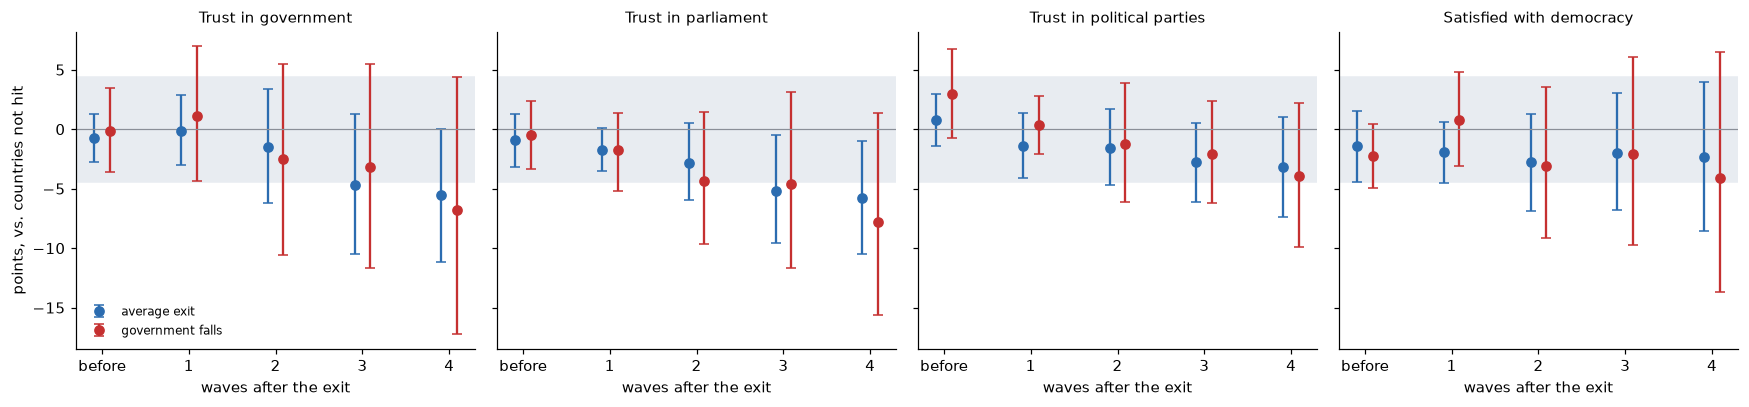

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, (o, label) in zip(axes, OUTCOMES.items()):
    for j, (kind, colr) in enumerate([('average exit', BLUE), ('government falls', RED)]):
        r = np.array([reading_b(o, h, kind) for h in [0] + HORIZONS])
        off = (j - 0.5) * 0.18
        ax.errorbar(np.array([0] + HORIZONS) + off, r[:, 0], yerr=[r[:, 0] - r[:, 1], r[:, 2] - r[:, 0]], fmt='o', color=colr, capsize=3, label=kind)
    ax.axhspan(-NOISE, NOISE, color=LIGHT, zorder=0); ax.axhline(0, color=GREY, lw=0.8)
    ax.set_xticks([0] + HORIZONS, ['before'] + [str(h) for h in HORIZONS]); ax.set_title(label, fontsize=10); ax.set_xlabel('waves after the exit')
axes[0].set_ylabel('points, vs. countries not hit'); axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 5. Each event on its own

The regression averages 22 very different episodes. This shows each one's own effect on a trust index (mean of government, parliament and parties) and on satisfaction with democracy: the change from the two waves before to the first and second wave after, **minus the same change over the same waves in countries with no cabinet ending and no scandal exit**. No regression, so what drives the average is visible.

In [7]:
ITEMS = ['trust_gov_pct', 'trust_parl_pct', 'trust_parties_pct']
all_end_dates = endings[['iso3', 'event_date']]
def locate(r, h):
    d, t = panel[panel.iso3 == r.iso3], r.decisive_date
    pre = d[d.fieldwork_end < t]
    if len(pre) < 2 or (t - pre.fieldwork_end.iloc[-1]).days > 240:
        return None
    c = d[(d.fieldwork_start >= t + pd.Timedelta(days=30)) & (d.fieldwork_median <= t + pd.Timedelta(days=240 + 183 * (h - 1)))]
    return None if len(c) < h else (pre.iloc[-2:], c.iloc[h - 1])

def event_did(r, h):
    loc = locate(r, h)
    if loc is None: return None
    base, post = loc
    s_, e_ = base.fieldwork_start.min(), post.fieldwork_end
    busy = set(endings[(endings.event_date >= s_) & (endings.event_date <= e_)].iso3) | set(ev[(ev.decisive_date >= s_) & (ev.decisive_date <= e_)].iso3)
    ctrl = [c for c in panel.iso3.unique() if c != r.iso3 and c not in busy and c != HELD_OUT]
    W = panel.set_index(['za', 'iso3'])
    zs = list(base.za) + [post.za]
    out = {}
    for name, items in [('trust_index', ITEMS), ('swd', ['swd_pct'])]:
        usable = [i for i in items if base[i].notna().all() and pd.notna(post[i])]
        if not usable: out[name] = np.nan; continue
        tv = post[usable].mean() - base[usable].mean(axis=1).mean()
        cs = []
        for k in ctrl:
            try: vals = [W.loc[(z, k), usable].mean(skipna=False) if len(usable) > 1 else W.loc[(z, k), usable[0]] for z in zs]
            except KeyError: continue
            if not np.isnan(vals).any(): cs.append(vals[-1] - np.mean(vals[:-1]))
        out[name] = tv - np.mean(cs) if len(cs) >= 5 else np.nan
    el = elections[(elections.iso3c == r.iso3) & (elections.edate >= base.fieldwork_start.iloc[-1]) & (elections.edate <= e_)]
    other = endings[(endings.iso3 == r.iso3) & (endings.event_date >= s_) & (endings.event_date <= e_) & ~endings.is_s3]
    out['election_in_window'] = bool(len(el)); out['other_ending_in_window'] = bool(len(other))
    return out

rows = []
for r in events.itertuples():
    row = {'event': r.event_id, 'level': r.level}
    for h in (1, 2):
        o_ = event_did(r, h)
        row.update({f'trust_index h{h}': np.nan, f'swd h{h}': np.nan} if o_ is None else {f'trust_index h{h}': o_['trust_index'], f'swd h{h}': o_['swd']})
        if o_ is not None and h == 2: row['election_in_window'], row['other_ending'] = o_['election_in_window'], o_['other_ending_in_window']
    rows.append(row)
evt = pd.DataFrame(rows)
display(evt.set_index('event').round(1))
print(f"Mean event effect on the trust index: h=1 {evt['trust_index h1'].mean():+.1f} (n={evt['trust_index h1'].notna().sum()}), h=2 {evt['trust_index h2'].mean():+.1f} (n={evt['trust_index h2'].notna().sum()}); median h=2 {evt['trust_index h2'].median():+.1f}; share negative at h=2: {(evt['trust_index h2'] < 0).sum()} of {evt['trust_index h2'].notna().sum()}")

,level,trust_index h1,swd h1,trust_index h2,swd h2,election_in_window,other_ending
event,,,,,,,
CZE_2005_Gross,pm_resigned,NaN,NaN,NaN,NaN,NaN,NaN
LVA_2007_Kalvitis,pm_resigned,-0.0,NaN,-2.4,NaN,False,False
IRL_2008_Ahern,pm_resigned,-0.0,NaN,-8.4,NaN,False,False
BEL_2008_Leterme,pm_resigned,-2.9,NaN,-0.7,NaN,False,False
DEU_2012_Wulff,head_of_state,6.6,NaN,8.3,NaN,False,False
HUN_2012_Schmitt,head_of_state,1.6,NaN,4.0,NaN,False,False
SVN_2013_Jansa,government_fell,-7.2,-6.9,-5.0,-9.5,False,False
CZE_2013_Necas,government_fell,3.9,3.2,9.3,8.9,True,True
LUX_2013_SREL,government_fell,-4.9,-2.7,-1.1,-0.8,True,False


Mean event effect on the trust index: h=1 -0.8 (n=20), h=2 -1.6 (n=17); median h=2 -1.1; share negative at h=2: 13 of 17


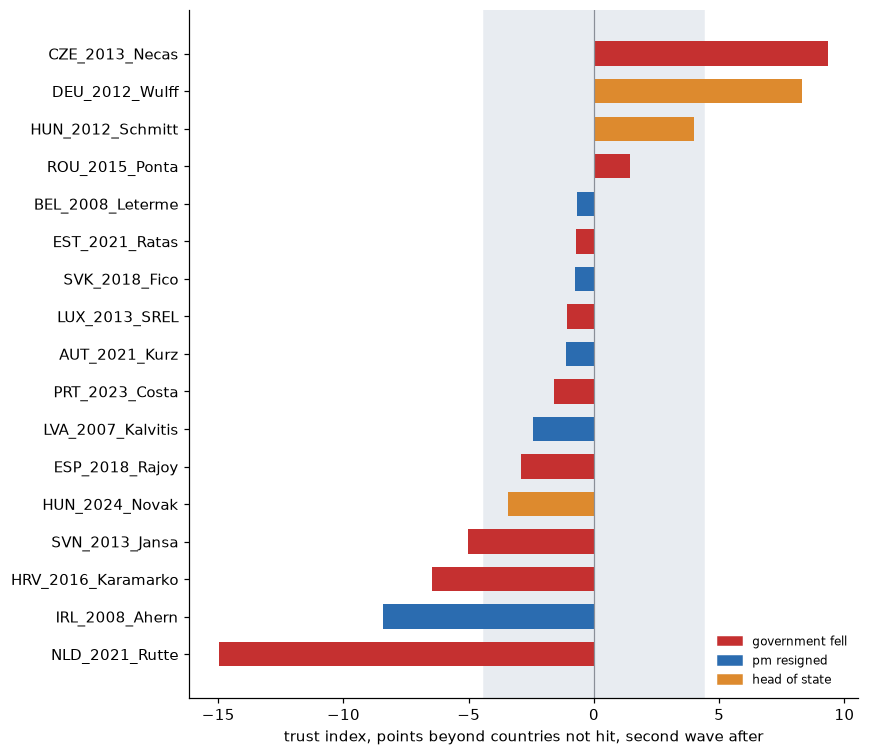

In [8]:
d_ = evt.dropna(subset=['trust_index h2']).sort_values('trust_index h2').reset_index(drop=True)
col = {'government_fell': RED, 'pm_resigned': BLUE, 'head_of_state': ORANGE}
fig, ax = plt.subplots(figsize=(8, 0.34 * len(d_) + 1.2))
ax.axvspan(-NOISE, NOISE, color=LIGHT, zorder=0); ax.axvline(0, color=GREY, lw=0.8)
ax.barh(range(len(d_)), d_['trust_index h2'], color=[col[l] for l in d_.level], height=0.65)
ax.set_yticks(range(len(d_)), d_.event); ax.set_xlabel('trust index, points beyond countries not hit, second wave after')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=l.replace('_', ' ')) for l, c in col.items()], frameon=False, fontsize=8, loc='lower right')
plt.tight_layout(); plt.show()

## 6. Does the answer depend on the choices?

Each row changes one thing; cells are the **average exit** at the **second wave after**, 90% wild-bootstrap range, with the number of exits. The checks: heads of state out; the Dutch institutional case out; Austria out (two exits); only **clean** exits (no election and no other cabinet ending in the window); no other-shock controls; the first version's timing (next wave, one baseline wave).

In [9]:
def variant(name, drop=(), h=2, **kw):
    ev_k = events[~events.event_id.isin(drop)] if len(drop) else events
    out = {'Variant': name}
    for o in OUTCOMES:
        s = build_sample(o, h, events_df=ev_k, **kw)
        s = s[s.iso3 != HELD_OUT].reset_index(drop=True)
        X = design(s, h=h, controls=CONTROLS if kw.get('use_controls', True) else ['later_on', 'pre_trend', 'growth', 'unemployment', 'inflation'])
        b, V, u, G = ols_cluster(s.dy, X, s.iso3.to_numpy())
        m = {'X': X, 's': s, 'u': u, 'b': b}
        ev_ = s[s.on == 1]; idx = list(b.index)
        x = np.zeros(len(idx)); x[idx.index('on')] = 1; x[idx.index('gov_fell')] = ev_.gov_fell.mean()
        th, lo, hi = wild_ci(m, x)
        out[OUTCOMES[o]] = f"{th[0]:+.1f} ({lo[0]:+.1f} to {hi[0]:+.1f})  n={int(s.on.sum())}"
    return out

clean_ids = set(evt[(~evt.election_in_window.fillna(True).astype(bool)) & (~evt.other_ending.fillna(True).astype(bool))].event)
sens = pd.DataFrame([
    variant('Main'),
    variant('Without head-of-state exits', drop=set(events[events.level == 'head_of_state'].event_id)),
    variant('Without the Dutch institutional case', drop={'NLD_2021_Rutte'}),
    variant('Without Austria (2 exits)', drop={'AUT_2019_Ibiza', 'AUT_2021_Kurz'}),
    variant('Clean exits only (no election or other cabinet ending in the window)', drop=set(events.event_id) - clean_ids),
    variant('No other-shock controls (S1 fall, bailout, energy)', use_controls=False),
    variant("First version's timing (next wave, one baseline wave)", exact=False),
]).set_index('Variant')
display(sens)
print('Clean exits kept:', ', '.join(sorted(clean_ids)) or 'none')

,Trust in government,Trust in parliament,Trust in political parties,Satisfied with democracy
Variant,,,,
Main,-1.5 (-6.2 to +3.4) n=13,-2.9 (-6.0 to +0.6) n=13,-1.6 (-4.7 to +1.7) n=14,-2.8 (-6.9 to +1.3) n=14
Without head-of-state exits,-2.3 (-7.6 to +3.0) n=11,-3.5 (-6.8 to -0.0) n=11,-2.7 (-5.8 to +0.7) n=12,-4.0 (-8.0 to +0.4) n=12
Without the Dutch institutional case,-0.1 (-4.5 to +4.2) n=12,-1.9 (-4.8 to +1.2) n=12,-0.6 (-3.3 to +2.1) n=13,-2.2 (-6.4 to +2.1) n=13
Without Austria (2 exits),-1.3 (-6.3 to +3.9) n=12,-3.0 (-6.4 to +0.7) n=12,-1.3 (-4.6 to +2.1) n=13,-2.1 (-6.2 to +2.1) n=13
Clean exits only (no election or other cabinet ending in the window),+0.3 (-5.5 to +5.8) n=8,-2.8 (-5.9 to +0.6) n=8,-1.1 (-4.8 to +2.3) n=8,-3.9 (-8.7 to +0.9) n=9
"No other-shock controls (S1 fall, bailout, energy)",-1.7 (-6.4 to +3.2) n=13,-3.0 (-6.2 to +0.4) n=13,-1.6 (-4.8 to +1.6) n=14,-2.8 (-7.0 to +1.1) n=14
"First version's timing (next wave, one baseline wave)",-1.1 (-4.0 to +1.8) n=20,-1.7 (-4.2 to +0.9) n=20,-1.3 (-3.8 to +1.1) n=20,-2.2 (-5.0 to +0.6) n=20


Clean exits kept: AUT_2021_Kurz, BEL_2008_Leterme, DEU_2012_Wulff, ESP_2018_Rajoy, EST_2021_Ratas, HUN_2012_Schmitt, HUN_2024_Novak, IRL_2008_Ahern, LVA_2007_Kalvitis, SVK_2018_Fico, SVN_2013_Jansa


In [10]:
# Leave one country out: average exit, second wave, trust in government and parliament
rows = []
for o in ['trust_gov', 'trust_parl', 'trust_parties', 'swd']:
    full = reading_b(o, 2, 'average exit')[0]
    drops = []
    for c in sorted(events.iso3.unique()):
        m = fit(o, 2, exclude=(HELD_OUT, c))
        x = combo(m, 'average exit')
        drops.append((c, float(x @ m['b'].to_numpy())))
    lo_, hi_ = min(drops, key=lambda z: z[1]), max(drops, key=lambda z: z[1])
    rows.append({'Outcome': OUTCOMES[o], 'all countries': f"{full:+.1f}", 'lowest when dropping': f"{lo_[1]:+.1f} (without {lo_[0]})", 'highest when dropping': f"{hi_[1]:+.1f} (without {hi_[0]})"})
display(pd.DataFrame(rows).set_index('Outcome'))

,all countries,lowest when dropping,highest when dropping
Outcome,,,
Trust in government,-1.5,-2.9 (without CZE),-0.1 (without NLD)
Trust in parliament,-2.9,-3.9 (without CZE),-2.0 (without NLD)
Trust in political parties,-1.6,-2.4 (without CZE),-0.6 (without NLD)
Satisfied with democracy,-2.8,-3.9 (without CZE),-2.0 (without HRV)


## 7. Back-test: leave one country out, against "no change"

For every country with a scandal exit, the model is estimated **without that country** and asked to predict each of its exits. Two scores, as in the E notebook: **coverage** of the 90% range (a wide enough range always covers), and **skill against "no change"** (mean absolute error of the prediction against that of predicting zero), with calibrated **conformal** ranges for a single episode.

In [11]:
def predict_rows(model, rows_all):
    b, V, u, G = model['b'], model['V'], model['u'], model['G']
    cols = list(b.index); cfe = [c for c in cols if c.startswith('c_')]
    sigma = np.sqrt(np.sum(u ** 2) / (len(u) - len(cols)))
    out = []
    for i, r in rows_all.iterrows():
        x = pd.Series(0.0, index=cols); x['const'] = 1.0
        for c in CONTROLS:
            if c in x.index: x[c] = r[c]
        if f"w_{r.wave}" in x.index: x[f"w_{r.wave}"] = 1.0
        other = float(x @ b) + b[cfe].sum() / (len(cfe) + 1)
        xs = pd.Series(0.0, index=cols)
        xs['on'], xs['gov_fell'] = 1.0, r.gov_fell
        m, se = float(xs @ b), float(np.sqrt(xs @ V @ xs))
        half = t90(G - 1) * np.sqrt(se ** 2 + sigma ** 2)
        out.append({'predicted': m, 'pred_low': m - half, 'pred_high': m + half, 'actual': r.dy - other, 'observed_change': r.dy})
    return pd.DataFrame(out, index=rows_all.index)

bt = []
for o in OUTCOMES:
    for h in HORIZONS:
        full = sample(o, h); ev_all = full[(full.on == 1) & (full.iso3 != HELD_OUT)]
        for iso3 in sorted(ev_all.iso3.unique()):
            rows_c = ev_all[ev_all.iso3 == iso3]
            mdl = fit(o, h, exclude=(HELD_OUT, iso3))
            bt.append(pd.concat([rows_c[['iso3', 'event_id', 'date']], predict_rows(mdl, rows_c)], axis=1).assign(scenario='S3', outcome=o, horizon=h))
backtest = pd.concat(bt).reset_index(drop=True)
backtest['inside'] = backtest.actual.between(backtest.pred_low, backtest.pred_high)
backtest['err_model'] = (backtest.actual - backtest.predicted).abs(); backtest['err_zero'] = backtest.actual.abs()

def conformal_q(scores, level=0.90):
    n = len(scores)
    return np.sort(scores)[min(n, int(np.ceil((n + 1) * level))) - 1]
crow = []
for (o, h), g in backtest.groupby(['outcome', 'horizon']):
    inside = []
    for c in g.iso3.unique():
        q_c = conformal_q(g[g.iso3 != c].err_model.to_numpy()); inside += list(g[g.iso3 == c].err_model <= q_c)
    crow.append({'outcome': o, 'horizon': h, 'exits': len(g), 'model coverage': g.inside.mean(), 'conformal coverage': float(np.mean(inside)), 'conformal_half_width': conformal_q(g.err_model.to_numpy()),
                 'MAE model': g.err_model.mean(), 'MAE no change': g.err_zero.mean(), 'corr(pred, actual)': g.predicted.corr(g.actual)})
conf = pd.DataFrame(crow)
conf['model beats no change'] = conf['MAE model'] < conf['MAE no change']
show_c = conf.assign(outcome=conf.outcome.map(OUTCOMES)).set_index(['outcome', 'horizon']).drop(columns='conformal_half_width').round(2)
display(show_c)
print(f"Coverage of single-episode ranges (target 0.90): model-based {conf['model coverage'].mean():.2f}, conformal {conf['conformal coverage'].mean():.2f}. The model beats 'no change' in {int(conf['model beats no change'].sum())} of {len(conf)} cells.")

exits  model coverage  conformal coverage  MAE model  MAE no change  corr(pred, actual)  model beats no change
outcome                    horizon                                                                                                                
Satisfied with democracy   1           15            0.87                0.93       5.98           5.06                0.02                  False
                           2           14            0.79                0.93       8.08           7.70               -0.89                  False
                           3           14            0.86                0.93       8.14           7.48               -0.87                  False
                           4           14            0.79                0.93       9.63           8.71               -0.42                  False
Trust in government        1           14            0.93                0.93       5.15           4.57               -0.44                  False
                           2           13            0.77                0.92       7.80           7.28               -0.66                  False
                           3           13            0.69                0.92      10.25          10.22               -0.71                  False
                           4           13            0.77                0.92       9.06           9.78               -0.65                   True
Trust in parliament        1           14            1.00                0.93       3.57           3.34               -0.97                  False
                           2           13            0.85                0.92       5.45           5.63               -0.24                   True
                           3           13            0.85                0.92       7.25           7.46               -0.89                   True
                           4           13            0.77                0.92       7.24           7.69               -0.19                   True
Trust in political parties 1           15            0.80                0.93       5.02           4.54               -0.18                  False
                           2           14            0.71                0.93       5.87           5.35               -0.90                  False
                           3           14            0.86                0.93       5.84           5.45               -0.70                  False
                           4           14            0.71                0.93       7.87           6.76               -0.72                  False

Coverage of single-episode ranges (target 0.90): model-based 0.81, conformal 0.93. The model beats 'no change' in 4 of 16 cells.


## 8. France: a what-if, and two scandals without an exit

France has **no scandal exit** in 2005–2025 under this rule: no prime minister or president left over an integrity allegation, and no government fell over one. So the readings for France are *what-ifs*: "if a head of government resigned over an integrity scandal" and so on. They are the same as for an average country, because country effects are absorbed.

As an **informal check**, two French scandals that did not end in an exit are run through the same event-level method: the **Cahuzac affair** (the budget minister, who had led the fight against tax fraud, resigned on 19 March 2013 and admitted a hidden Swiss account) and the **Fillon affair** (the presidential candidate, revealed on 25 January 2017 to have paid his family for work that may not have been done). These are *not* scandal exits as defined here, so the model makes no prediction for them; the comparison asks only whether French trust moved by anything like the model's size.

In [12]:
fr_base = {'trust_gov': 21, 'trust_parl': 23, 'trust_parties': 12, 'swd': 56}
rows = []
for o in OUTCOMES:
    row = {'Outcome': OUTCOMES[o], 'France today (EB 105.2)': f"{fr_base[o]}%"}
    for kind in ['top person leaves, government continues', 'government falls']:
        row[kind + ', h = 2'] = fmt(reading_b(o, 2, kind))
    rows.append(row)
print('France what-if, second wave after, points (90% range):'); display(pd.DataFrame(rows).set_index('Outcome'))

french = pd.DataFrame({'event_id': ['FRA_2013_Cahuzac', 'FRA_2017_Fillon'], 'iso3': 'FRA', 'decisive_date': pd.to_datetime(['2013-03-19', '2017-01-25'])})
rows = []
for r in french.itertuples():
    row = {'case': r.event_id}
    for h in (1, 2):
        o_ = event_did(r, h)
        row[f'trust index, h = {h}'] = np.nan if o_ is None else o_['trust_index']; row[f'satisfaction, h = {h}'] = np.nan if o_ is None else o_['swd']
    rows.append(row)
fr_cases = pd.DataFrame(rows).set_index('case')
print('Two French scandals without an exit: change beyond countries not hit (points):'); display(fr_cases.round(1))
m_idx = [reading_b(o, 2, 'average exit') for o in ('trust_gov', 'trust_parl', 'trust_parties')]
print('For comparison, the model average exit at h = 2: ' + ', '.join(f"{OUTCOMES[o].lower()} {fmt(r_)}" for o, r_ in zip(('trust_gov', 'trust_parl', 'trust_parties'), m_idx)))

France what-if, second wave after, points (90% range):


,France today (EB 105.2),"top person leaves, government continues, h = 2","government falls, h = 2"
Outcome,,,
Trust in government,21%,-0.3 (-4.4 to +3.9),-2.5 (-10.6 to +5.5)
Trust in parliament,23%,-1.1 (-4.3 to +2.4),-4.4 (-9.6 to +1.4)
Trust in political parties,12%,-2.1 (-6.9 to +2.8),-1.2 (-6.1 to +3.9)
Satisfied with democracy,56%,-2.5 (-9.5 to +3.9),-3.1 (-9.1 to +3.6)


Two French scandals without an exit: change beyond countries not hit (points):


,"trust index, h = 1","satisfaction, h = 1","trust index, h = 2","satisfaction, h = 2"
case,,,,
FRA_2013_Cahuzac,-10.7,-7.6,-15.9,-14.4
FRA_2017_Fillon,-0.3,NaN,9.2,10.6


For comparison, the model average exit at h = 2: trust in government -1.5 (-6.2 to +3.4), trust in parliament -2.9 (-6.0 to +0.6), trust in political parties -1.6 (-4.7 to +1.7)


## 9. The party system (secondary output)

The specification lists the party system among the variables hit. For each exit followed by a parliamentary election within three years, this compares the **change in the effective number of parties** (and in turnout) from the last election before the exit to the first after, with the **average change in the other EU countries over the same two dates** (`build_s1_dataset.py`'s matched comparison). Alliance member parties count as one list. Descriptive: a few elections, and an election after a scandal is not a clean experiment.

In [13]:
rows = []
for r in events.itertuples():
    o_ = b1.election_outcomes(elections, r.iso3, r.decisive_date)
    if pd.isna(o_.get('next_election_gap_days', np.nan)) or o_['next_election_gap_days'] > 3 * 365 or 'effective_parties_change' not in o_:
        continue
    m_e, n_e = b1.matched_change(elections, r.iso3, r.decisive_date, 'effective_parties')
    m_t, n_t = b1.matched_change(elections, r.iso3, r.decisive_date, 'turnout_pct', skip_compulsory=True)
    rows.append({'event': r.event_id, 'days to next election': int(o_['next_election_gap_days']), 'effective parties: change': o_['effective_parties_change'], 'matched change': m_e,
                 'excess': o_['effective_parties_change'] - m_e, 'turnout: change (pp)': o_['turnout_change_pp'], 'matched change (pp)': m_t,
                 'turnout excess (pp)': np.nan if o_.get('compulsory_voting') else o_['turnout_change_pp'] - m_t})
ps = pd.DataFrame(rows).set_index('event')
display(ps.round(2))
by_c = ps.assign(iso3=[i[:3] for i in ps.index]).groupby('iso3')[['excess', 'turnout excess (pp)']].mean()
def trange(x):
    x = x.dropna(); n = len(x)
    return (x.mean(), x.mean() - t90(n - 1) * x.std(ddof=1) / np.sqrt(n), x.mean() + t90(n - 1) * x.std(ddof=1) / np.sqrt(n), n) if n >= 3 else (x.mean(), np.nan, np.nan, n)
te, tt = trange(by_c['excess']), trange(by_c['turnout excess (pp)'])
print(f"Effective number of parties beyond the matched change: {te[0]:+.2f} (90% range {te[1]:+.2f} to {te[2]:+.2f}, {te[3]} countries). Turnout: {tt[0]:+.1f} pp ({tt[1]:+.1f} to {tt[2]:+.1f}, {tt[3]} countries).")

,days to next election,effective parties: change,matched change,excess,turnout: change (pp),matched change (pp),turnout excess (pp)
event,,,,,,,
CZE_2005_Gross,404,-0.82,0.18,-1.00,6.47,-3.54,10.01
LVA_2007_Kalvitis,1060,-2.89,0.38,-3.28,3.74,-1.53,5.28
IRL_2008_Ahern,1059,0.73,0.32,0.41,2.87,-1.53,4.40
BEL_2008_Leterme,541,0.93,0.15,0.77,-1.86,-0.67,NaN
DEU_2012_Wulff,583,-0.79,0.42,-1.21,0.74,-1.72,2.46
HUN_2012_Schmitt,734,0.35,0.54,-0.19,-2.54,-1.55,-0.99
SVN_2013_Jansa,501,-0.20,0.57,-0.77,-13.88,-1.17,-12.71
CZE_2013_Necas,131,0.89,0.53,0.36,-3.06,-1.37,-1.70
LUX_2013_SREL,102,0.53,0.55,-0.01,0.40,-1.44,NaN


Effective number of parties beyond the matched change: -0.16 (90% range -0.57 to +0.25, 17 countries). Turnout: -0.8 pp (-3.4 to +1.9, 15 countries).


## 10. Tables

Written to `outputs/model/` as `s3_*`, in the layout of `e_effects.csv`:

- `s3_effects.csv`: base effect and the two additions per outcome and horizon, wild-bootstrap and t-ranges.
- `s3_reading.csv`: the reading for each kind of exit (and the average) per outcome and horizon, with the single-episode half-width.
- `s3_event_effects.csv`: each event's own effect (section 5).
- `s3_backtest.csv`, `s3_conformal.csv`: the leave-one-country-out predictions and the calibrated ranges.

In [14]:
rows = []
PN = {'on': 'scandal_exit', 'gov_fell': 'government_fell'}
for (o, h), m in models.items():
    idx = list(m['b'].index); C = np.zeros((len(PN), len(idx)))
    for i, t_ in enumerate(PN): C[i, idx.index(t_)] = 1.0
    th, lo, hi = wild_ci(m, C); c = t90(m['G'] - 1)
    for i, (t_, name) in enumerate(PN.items()):
        se = np.sqrt(m['V'].loc[t_, t_])
        rows.append({'shock': 'S3', 'parameter': name, 'outcome': o, 'horizon': h, 'effect_per_unit': th[i], 'ci_low': lo[i], 'ci_high': hi[i],
                     'ci_low_t': m['b'][t_] - c * se, 'ci_high_t': m['b'][t_] + c * se, 'n_events': m['n_events'], 'n_obs': m['n_obs'], 'estimated_without': HELD_OUT})
pd.DataFrame(rows).round(4).to_csv(OUTDIR / 's3_effects.csv', index=False)
rd = []
for o in OUTCOMES:
    plac = reading_b(o, 0, 'average exit')
    for h in HORIZONS:
        qh = float(conf[(conf.outcome == o) & (conf.horizon == h)].conformal_half_width.iloc[0])
        for kind in KINDS:
            m_, lo_, hi_ = reading_b(o, h, kind)
            rd.append({'outcome': o, 'horizon': h, 'kind': kind, 'reading': m_, 'ci_low': lo_, 'ci_high': hi_, 'one_episode_half_width': qh, 'placebo_clean': bool(plac[1] <= 0 <= plac[2]),
                       'verdict': 'detectable change (range excludes zero)' if (lo_ > 0 or hi_ < 0) else 'no detectable change', 'n_events': models[(o, h)]['n_events']})
pd.DataFrame(rd).round(3).to_csv(OUTDIR / 's3_reading.csv', index=False)
evt.round(3).to_csv(OUTDIR / 's3_event_effects.csv', index=False)
backtest.assign(date=pd.to_datetime(backtest.date).dt.strftime('%Y-%m-%d')).round(3).to_csv(OUTDIR / 's3_backtest.csv', index=False)
conf.round(3).to_csv(OUTDIR / 's3_conformal.csv', index=False)
print('Wrote', ', '.join(p.name for p in sorted(OUTDIR.glob('s3_*'))))

Wrote s3_backtest.csv, s3_conformal.csv, s3_effects.csv, s3_event_effects.csv, s3_reading.csv


## 11. What this says, and what it does not

In [15]:
lines = ['**What the panel says**', '']
m1 = models[('trust_gov', 2)]
lines.append(f"- **{m1['n_events']} scandal exits** in {m1['event_countries']} EU countries (of {len(events)} listed; France excluded) stand behind the second-wave estimates.")
for o, label in OUTCOMES.items():
    cells_ = []
    for h in (1, 2, 3):
        r_ = reading_b(o, h, 'average exit'); cells_.append(f"h={h} {fmt(r_)}{' *' if (r_[1] > 0 or r_[2] < 0) else ''}")
    lines.append(f"- **{label}**, average exit: " + '; '.join(cells_) + '.')
lines.append('  (* = range excludes zero; every other reading is *no detectable change*.)')
bad = [OUTCOMES[o] for o in OUTCOMES if not (reading_b(o, 0, 'average exit')[1] <= 0 <= reading_b(o, 0, 'average exit')[2])]
lines.append('- **Placebo:** ' + ('clean for every outcome.' if not bad else 'not clean for ' + ', '.join(bad) + ': trust was already moving before those exits (a scandal builds for weeks before the resignation).'))
diff = {}
for o in OUTCOMES:
    m_ = models[(o, 2)]; idx_ = list(m_['b'].index); c_ = np.zeros(len(idx_)); c_[idx_.index('gov_fell')] = 1.0
    th_, lo_, hi_ = wild_ci(m_, c_); diff[o] = (float(th_[0]), float(lo_[0]), float(hi_[0]))
lines.append('- **Government falls vs. only the top person leaving**, second wave, the extra effect when the government falls: ' + '; '.join(f"{OUTCOMES[o].lower()} {fmt(diff[o])}" for o in OUTCOMES) + '.')
sk = int(conf['model beats no change'].sum())
lines.append(f"- **Back-test:** model-based single-episode ranges cover {conf['model coverage'].mean():.0%}, conformal {conf['conformal coverage'].mean():.0%}; the model beats 'no change' in {sk} of {len(conf)} cells (median correlation between predicted and actual {conf['corr(pred, actual)'].median():.2f}).")
n_neg = int((evt['trust_index h2'] < 0).sum()); n_all = int(evt['trust_index h2'].notna().sum())
lines.append(f"- **Event by event** (trust index, second wave): {n_neg} of {n_all} exits are negative; the median is {evt['trust_index h2'].median():+.1f}, the mean {evt['trust_index h2'].mean():+.1f}.")
lines.append(f"- **Party system:** effective number of parties {te[0]:+.2f} beyond the matched change ({te[3]} countries" + (f", range {te[1]:+.2f} to {te[2]:+.2f})" if pd.notna(te[1]) else ', too few for a range)') + '.')
display(Markdown('\n'.join(lines)))

**What the panel says**

- **13 scandal exits** in 13 EU countries (of 22 listed; France excluded) stand behind the second-wave estimates.
- **Trust in government**, average exit: h=1 -0.1 (-3.0 to +2.9); h=2 -1.5 (-6.2 to +3.4); h=3 -4.7 (-10.5 to +1.2).
- **Trust in parliament**, average exit: h=1 -1.7 (-3.5 to +0.1); h=2 -2.9 (-6.0 to +0.6); h=3 -5.2 (-9.5 to -0.5) *.
- **Trust in political parties**, average exit: h=1 -1.4 (-4.1 to +1.4); h=2 -1.6 (-4.7 to +1.7); h=3 -2.8 (-6.1 to +0.5).
- **Satisfied with democracy**, average exit: h=1 -1.9 (-4.5 to +0.6); h=2 -2.8 (-6.9 to +1.3); h=3 -2.0 (-6.8 to +3.0).
  (* = range excludes zero; every other reading is *no detectable change*.)
- **Placebo:** clean for every outcome.
- **Government falls vs. only the top person leaving**, second wave, the extra effect when the government falls: trust in government -2.2 (-10.3 to +5.7); trust in parliament -3.2 (-9.2 to +2.8); trust in political parties +0.8 (-4.8 to +6.8); satisfied with democracy -0.5 (-8.6 to +8.0).
- **Back-test:** model-based single-episode ranges cover 81%, conformal 93%; the model beats 'no change' in 4 of 16 cells (median correlation between predicted and actual -0.68).
- **Event by event** (trust index, second wave): 13 of 17 exits are negative; the median is -1.1, the mean -1.6.
- **Party system:** effective number of parties -0.16 beyond the matched change (17 countries, range -0.57 to +0.25).

**What it cannot show**

- **The selection rule is the weak point.** The events are scandals big enough to remove a head of government, a head of state or a cabinet. Scandals that were survived (Berlusconi's, Fillon's, Cahuzac's in France, Tusk's "waiter tapes" in Poland, Gyurcsány's 2006 speech in Hungary) are not in the sample, and the exit itself, with the resignation, the new leader and often an election, is part of what is measured. This is "the effect of a scandal that ends in an exit", not "the effect of a scandal".
- **Coded by one reviewer.** Dates, the level reached and the integrity classification are from news reports checked by one person; `checked_by_person` is `no` for every row. Four cases are judgement calls (Ahern, whether the tribunal caused it; Ponta, a nightclub fire as well as a corruption trial; Fico, the murder of a journalist; Rutte, institutional wrongdoing).
- **Few exits, few countries.** 13 to 15 exits after the timing rule (the rule drops about 40% of the 22 listed, mostly because the decisive date falls within a month of the next wave), two each in Austria, Czechia, Portugal and Hungary. A real effect of a point or two would not show up, and any split by kind of exit (government fell or not) rests on six or seven exits per group.
- **Not a cause.** A scandal and a fall in trust can share a cause; the placebo is the check, and a scandal builds for weeks before the resignation, so the "before" waves may already be low.
- **Overlap with S1.** Five of these exits are also in the S1 sample (Austria 2019, Spain 2018, Luxembourg 2013, Slovenia 2013, Portugal 2025), where the first S1 notebook counts them as government falls. Here they count only as S3, as the scope documents require; S1 should be re-run without them for the two to be consistent.
- **France has no exit,** so no out-of-sample test on its own events. The two French scandals shown are informal.
- **Not yet in:** the *size* of a scandal (how long it ran, how widely it was covered), radical vote at the next election, and Italy 1992–94 (before comparable trust data).